# Chile: CMF B-1, IFRS 9 y el Anejo 9 del Banco de España sobre una misma cartera (Banco Andino)

**Pregunta:** ¿Cuánta provisión registra un banco chileno sintético bajo el método estándar B-1 de la CMF, cuánta darían IFRS 9 y el Anexo 9 del Banco de España sobre los mismos préstamos, y qué explica la brecha entre ellas?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 04 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- decir por qué los bancos chilenos no contabilizan el deterioro de IFRS 9 sobre los préstamos, y de dónde vienen las provisiones B-1 de la CMF;
- leer el método estándar B-1, el factor $PE = PI \times PDI$ por grupo, la regla del máximo entre el método estándar y uno interno, el mínimo de 0,50 % y las provisiones adicionales, y calcular cada uno con el motor sobre cuentas construidas;
- leer las tablas de cobertura del Anejo 9 del Banco de España y la correspondencia de sus categorías con las etapas de IFRS 9;
- provisionar un banco sintético bajo los tres regímenes, y leer la brecha entre B-1 e IFRS 9 como un puente de decisiones de medición;
- decir qué pasa con la brecha entre los regímenes cuando la economía se tensiona de cinco maneras distintas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
SEGMENT = {
    "mortgage-ltv-le80": "hipotecarios hasta 80% de préstamo sobre garantía",
    "mortgage-ltv-gt80": "hipotecarios sobre 80% de préstamo sobre garantía",
    "consumer-instalment": "consumo en cuotas",
    "consumer-cards": "tarjetas de consumo",
    "commercial-group": "comerciales, evaluación grupal",
    "commercial-individual": "comerciales, evaluación individual",
}
STEP = {
    "measurement-basis": "base de medición", "lifetime-horizon": "horizonte de vida completa",
    "forward-looking": "ponderación de escenarios", "discounting": "descuento",
    "b1-minimum-top-up": "mínimo B-1", "ifrs9-overlays": "ajustes",
}
SCENARIO = {
    "base": "base", "recession": "recesión", "house-price-fall": "precios de viviendas",
    "consumer-arrears-shock": "mora de consumo", "uf-inflation-spike": "inflación UF",
    "combined-severe": "combinado severo",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C07, **Banco Andino**, un banco **sintético** generado y calibrado a agregados públicos de la CMF, la Comisión para el Mercado Financiero de Chile. No es un banco real ni evidencia sobre ningún banco; el aviso versionado lo dice, y el notebook lo imprime. Su cartera tiene seis segmentos (hipotecarios por razón préstamo a garantía, consumo en cuotas, tarjetas, y comerciales de evaluación grupal o individual) y unas 171.000 cuentas, en pesos chilenos (CLP). La misma cartera se provisiona bajo tres regímenes y seis escenarios, un archivo cada uno.

- **Archivos que se leen:** `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` y `combined-severe.json`, y `data/derived/C07/models-banco-andino.json` para las ranuras de modelo. En cada archivo de escenario: `outputs.comparison` (las tres provisiones por segmento), `outputs.gap_bridge`, `outputs.b1_detail`, `outputs.ifrs9_detail`, `outputs.bde_detail` y, desde el segundo escenario, `outputs.delta_vs_base`.
- **Los regímenes:** CMF B-1 es la provisión estatutaria que los bancos chilenos contabilizan sobre los préstamos; la columna IFRS 9 es una **medida de comparación** y no lo que contabilizan los bancos chilenos (el capítulo A-2 N 5 del CNCB deja los préstamos a B-1); el Anejo 9 del Banco de España es la solución alternativa del PCGA español.
- **Supuestos del caso:** los choques de los escenarios, los ajustes y las provisiones adicionales son supuestos del caso, no trayectorias ni datos chilenos.

La celda siguiente carga los seis escenarios y el archivo de modelos e imprime el aviso versionado, las casillas de modelo y las versiones del motor.

In [2]:
# Cargar los seis escenarios de Banco Andino e imprimir el aviso, las casillas de modelo y las versiones
from riskvalidation.provisions import local_cl as cl, local_es as es

LANG = "es"
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C07"
scenarios = {n: json.loads((DERIVED / f"{n}.json").read_text(encoding="utf-8")) for n in SCENARIO}
models = json.loads((DERIVED / "models-banco-andino.json").read_text(encoding="utf-8"))
base_art = scenarios["base"]
out = base_art["outputs"]
print(out["notice"][LANG])
baked = sorted({s["provenance"]["riskvalidation_version"] for s in scenarios.values()})
print("motor que calculó los seis escenarios:", *baked)
print("motor instalado ahora:", md.version("riskvalidation"))
print("casillas de modelo:", len(models["model"]))
print("cuentas:", sum(seg["accounts"] for seg in out["portfolio"]["segments"]))
gross_total = sum(seg["gross_exposure"] for seg in out["portfolio"]["segments"])
print("exposición bruta, CLP miles de millones:", round(gross_total / 1e9, 1))

Datos sintéticos: Banco Andino es un banco generado, calibrado a agregados públicos del sistema de la CMF; no es un banco real ni evidencia sobre ningún banco. CMF B-1 es la provisión estatutaria que los bancos chilenos constituyen sobre colocaciones; la columna IFRS 9 es una medida de comparación, no la provisión que los bancos chilenos constituyen sobre colocaciones (CNCB A-2 N° 5 deja las colocaciones a B-1); el Anejo 9 del BdE es la solución alternativa del PGC español. Montos en CLP.
motor que calculó los seis escenarios: 1.0.1
motor instalado ahora: 1.0.1
casillas de modelo: 4
cuentas: 171500
exposición bruta, CLP miles de millones: 6000.0


## Método

**Por qué tres regímenes.** Los bancos chilenos adoptaron IFRS 9 en el compendio contable de la CMF (CNCB) en 2022 **salvo** el capítulo de deterioro para préstamos: las provisiones sobre préstamos y créditos contingentes siguen bajo los capítulos B-1 a B-3 (CNCB A-2 N 5). La provisión B-1 es una fórmula supervisora, no una pérdida crediticia esperada. Los bancos españoles, bajo la Circular 4/2017 del Banco de España, sí aplican el modelo de IFRS 9, con «soluciones alternativas» supervisoras para la estimación colectiva. Contraste provisiona un banco sintético bajo los tres, para mostrar dónde coinciden y dónde no.

**CMF B-1, los métodos estándar** (CNCB B-1 N 3). Para una cartera grupal el factor de provisión es el producto de la probabilidad de incumplimiento y la pérdida dado el incumplimiento de la celda de una tabla, por grupo de exposición y días de mora:

$$PE = PI \times PDI, \qquad \mathrm{Prov}_{\mathrm{grupo}} = EG\,(1 - s)\,PE_{\mathrm{grupo}} + EG\,s\,PE_{\mathrm{avalista}}, \qquad \mathrm{Prov} = \max\bigl(\mathrm{Prov}^{\mathrm{estándar}}, \mathrm{Prov}^{\mathrm{interno}}\bigr)$$

con $EG$ la exposición del grupo y $s$ la fracción garantizada (B-1 N 4.1); la regla del máximo se aplica salvo que el método interno tenga la «no objeción» de la CMF (B-1 N 3). Un deudor evaluado individualmente tiene una categoría A1 a A6 (normal) o B1 a B4 (subestándar) con su propio $PE$ (N 2.1). La provisión mínima de 0,50 % se aplica solo a la cartera normal evaluada individualmente, y las provisiones adicionales (contracíclicas) son una línea separada, dentro de los límites de la política del directorio y nunca parte del total comparable (N 9).

**El Anejo 9 del Banco de España** (Circular 4/2017, modificada por la Circular 6/2021, tablas de los puntos 140, 144 y 172 desde el 30 de junio de 2022). La cobertura es un coeficiente del monto no cubierto por garantías eficaces, por segmento y categoría de riesgo:

$$\mathrm{Cobertura} = c_{s,k}\,\max\Bigl(0,\ \mathrm{EAD} - \sum_g \mathrm{ValorAjustado}_g\Bigr)$$

con el riesgo normal y normal en vigilancia especial por el punto 144, el riesgo dudoso por morosidad por el punto 140, y la correspondencia de categorías a etapas (normal a la Etapa 1, vigilancia especial a la Etapa 2, dudoso a la Etapa 3).

**IFRS 9 como medida de comparación** es la PCE ponderada por probabilidad de los notebooks 01 a 03 con los ajustes como líneas separadas (notebook 04). Las funciones del motor calculan y no declaran cumplimiento; los números de punto del Anejo 9 son los de la Circular 6/2021 y si cambiaron después de la Circular 1/2025 no se verifica aquí.

### Paso 1: la tabla hipotecaria B-1, celda por celda

El motor guarda las tablas B-1 transcritas celda por celda, con el párrafo de la fuente en el código. `b1_mortgage_pe` devuelve, para una razón préstamo sobre garantía (PVG) y un tramo de mora, la probabilidad de incumplimiento $PI$, la pérdida dado el incumplimiento $PDI$ y su producto $PE$. La llamamos sobre cuentas construidas, cuatro niveles de PVG en una tabla y una grilla fina de PVG para cada uno de los cinco tramos de mora en la figura, para ver la forma de la tabla con que se provisiona toda la cartera hipotecaria del banco.

PVG 0.35 | PI 0.010916 | PDI 0.000225 | PE 0.000002 | PI x PDI 0.000002
PVG 0.60 | PI 0.019158 | PDI 0.021955 | PE 0.000421 | PI x PDI 0.000421
PVG 0.85 | PI 0.025150 | PDI 0.215527 | PE 0.005421 | PI x PDI 0.005421
PVG 0.95 | PI 0.027400 | PDI 0.272000 | PE 0.007453 | PI x PDI 0.007453


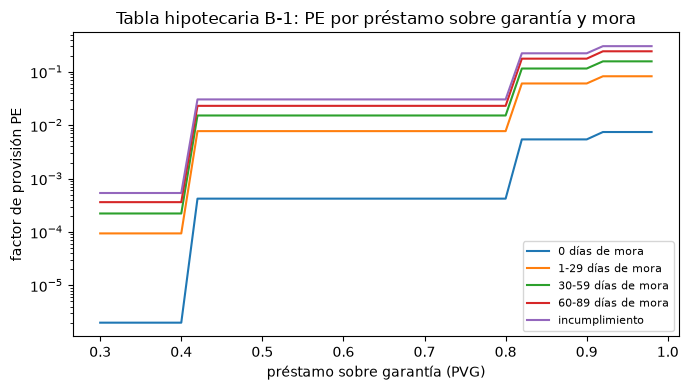

In [3]:
# Leer la tabla hipotecaria B-1 en cuatro niveles de préstamo sobre garantía y dibujar la PE por tramo de mora
for pvg in (0.35, 0.60, 0.85, 0.95):
    pi, pdi, pe_cell = cl.b1_mortgage_pe(pvg, "0")
    print(f"PVG {pvg:.2f} | PI {pi:.6f} | PDI {pdi:.6f} | PE {pe_cell:.6f} | PI x PDI {pi * pdi:.6f}")
grid = np.linspace(0.30, 0.98, 35)
buckets = ("0", "1-29", "30-59", "60-89", "default")
curves = {bucket: [cl.b1_mortgage_pe(float(v), bucket)[2] for v in grid] for bucket in buckets}

fig, ax = plt.subplots(figsize=(7, 4))
for bucket in buckets:
    label = "incumplimiento" if bucket == "default" else f"{bucket} días de mora"
    ax.plot(grid, curves[bucket], label=label)
ax.set_yscale("log")
ax.set_xlabel("préstamo sobre garantía (PVG)")
ax.set_ylabel("factor de provisión PE")
ax.set_title("Tabla hipotecaria B-1: PE por préstamo sobre garantía y mora")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Para una hipoteca con una razón préstamo sobre garantía entre 40% y 80% y sin mora la tabla da $PI = 0{,}019158$ y $PDI = 0{,}021955$, de modo que $PE = 0{,}000421$, y el producto impreso de los dos factores es el mismo número. Las curvas suben con fuerza con la razón préstamo sobre garantía y con la mora: el factor en PVG 0,35 es 0,000002 y en incumplimiento en el extremo superior llega a 0,302436, cinco órdenes de magnitud de distancia. Los escalones de cada curva son los límites de las celdas de la tabla, de modo que la provisión de una hipoteca la decide la celda en que cae y no un modelo suave.

### Paso 2: las celdas comerciales, de consumo e individuales

Los préstamos comerciales grupales tienen una tabla por días de mora y por la razón entre el préstamo y el valor de su garantía (PTVG), los de consumo una tabla por mora y por si el deudor tiene una hipoteca en el sistema, y un deudor evaluado individualmente tiene una categoría A1 a A6 o B1 a B4 con su propio factor. La celda llama a las búsquedas del motor sobre cuentas construidas, un caso cada una, y pide luego un tramo de mora que la tabla no tiene, para ver al motor rechazarlo y no adivinar.

In [4]:
# Leer las celdas comerciales, de consumo e individuales de B-1 para cuentas construidas
print("comercial, al día, garantía con PTVG 0.8 y sin garantía (PI, PDI, PE):")
print([round(v, 6) for v in cl.b1_commercial_pe("0", 0.8)], [round(v, 6) for v in cl.b1_commercial_pe("0", None)])
print("consumo en cuotas, 5 días de atraso, hipoteca en el sistema, sin mora (PI, PDI, PE):")
print([round(v, 6) for v in cl.b1_consumer_pe(5, True, False, "instalment")])
print("categorías individuales (PI, PDI, PE):")
for category in ("A1", "A4", "B4"):
    print(category, [round(v, 6) for v in cl.b1_individual_category(category)])
print("provisión grupal, exposición 1000, PE del grupo 0.05, parte garantizada 0.20, PE del garante 0.01:")
print(round(cl.b1_group_provision(1000.0, 0.05, 0.20, 0.01), 4))
try:
    cl.b1_mortgage_pe(0.6, "45")
except ValueError as error:
    print("un tramo que la tabla no tiene se rechaza con", type(error).__name__)

comercial, al día, garantía con PTVG 0.8 y sin garantía (PI, PDI, PE):
[0.0186, 0.322, 0.005989] [0.0491, 0.569, 0.027938]
consumo en cuotas, 5 días de atraso, hipoteca en el sistema, sin mora (PI, PDI, PE):
[0.033, 0.477, 0.015741]
categorías individuales (PI, PDI, PE):
A1 [0.0004, 0.9, 0.00036]
A4 [0.02, 0.875, 0.0175]
B4 [0.45, 0.975, 0.43875]
provisión grupal, exposición 1000, PE del grupo 0.05, parte garantizada 0.20, PE del garante 0.01:
42.0
un tramo que la tabla no tiene se rechaza con ValueError


Un préstamo comercial al día con una garantía a un PTVG de 0,8 lleva un factor de 0,005989 y sin garantía 0,027938, de modo que la garantía divide la provisión casi por cinco. El préstamo de consumo en cuotas del ejemplo lleva 0,015741. Las categorías individuales suben de 0,00036 para A1 a 0,0175 para A4 y 0,43875 para B4, un factor de más de mil entre el mejor deudor normal y uno subestándar. Cada uno de estos es una búsqueda en una tabla, y el rechazo del tramo `45` muestra que las tablas son cerradas: una entrada que no es una celda es un error.

### Paso 3: la provisión grupal, la regla del máximo, el mínimo y las provisiones adicionales

`b1_group_provision` calcula $EG(1-s)PE + EG\,s\,PE_{\mathrm{garante}}$; `b1_group_max_rule` devuelve la mayor entre la provisión estándar y la interna salvo que el método interno tenga la no objeción de la CMF, y la estándar cuando no hay método interno; `b1_minimum_normal_check` prueba el mínimo de 0,50% de la cartera normal individual; `b1_additional_provisions` acepta un monto solo dentro del rango de política del directorio. La celda las corre sobre un ejemplo construido y sobre el detalle versionado de Banco Andino, y dibuja la regla del máximo de cada segmento grupal.

In [5]:
# Calcular las reglas grupales, el mínimo y las provisiones adicionales sobre el detalle versionado
detail = out["b1_detail"]
rows = detail["group_max_rule"]
applied = [cl.b1_group_max_rule(r["standard"], r["internal"])[0] for r in rows]
print("aplicada, CLP millones:", [round(a / 1e6, 1) for a in applied])
minimum = detail["minimum_check"]
exposure, before = minimum["normal_portfolio_exposure"], minimum["normal_portfolio_provision_before_minimum"]
check = cl.b1_minimum_normal_check(exposure, before)
tight = cl.b1_minimum_normal_check(exposure, 5e9)
print("mínimo de la cartera normal, CLP millones:", round(check.minimum_amount / 1e6, 1))
print("vinculante:", "sí" if check.binding else "no", "| complemento, CLP millones:", round(check.top_up / 1e6, 1))
print("complemento con una provisión de 5 mil millones, CLP millones:", round(tight.top_up / 1e6, 1))
extra = detail["additional_provisions"]
accepted = cl.b1_additional_provisions(extra["amount"], extra["policy_min"], extra["policy_max"])
print("provisiones adicionales dentro de la política, CLP millones:", accepted / 1e6)
try:
    cl.b1_additional_provisions(20e9, extra["policy_min"], extra["policy_max"])
except ValueError as error:
    print("fuera de la política se rechaza con", type(error).__name__)

aplicada, CLP millones: [1626.7, 11229.1, 29229.0, 26899.5, 24191.8]
mínimo de la cartera normal, CLP millones: 8457.4
vinculante: no | complemento, CLP millones: 0.0
complemento con una provisión de 5 mil millones, CLP millones: 3457.4
provisiones adicionales dentro de la política, CLP millones: 3000.0
fuera de la política se rechaza con ValueError


La provisión grupal del ejemplo es 42,0, la fórmula con sus tres insumos; las provisiones aplicadas, el mínimo con su complemento y las provisiones adicionales están en la salida anterior. La celda siguiente dibuja la regla del máximo para los cinco segmentos grupales del detalle versionado.

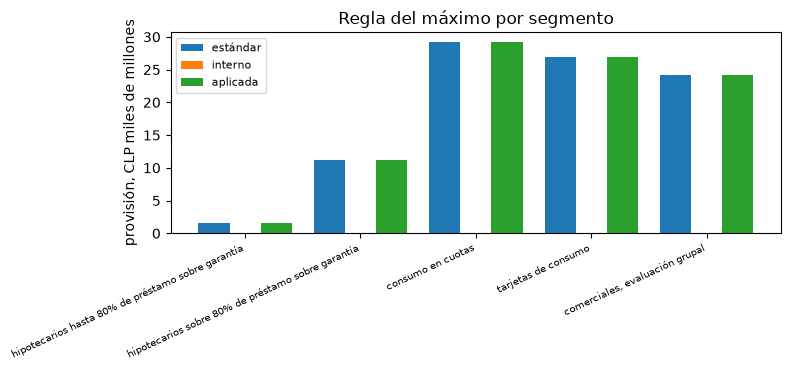

In [6]:
# Dibujar la regla del máximo: la provisión estándar, la interna y la aplicada de cada segmento grupal
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(8, 3.8))
internal = [float("nan") if r["internal"] is None else r["internal"] / 1e9 for r in rows]
series = (([r["standard"] / 1e9 for r in rows], "tab:blue", "estándar"), (internal, "tab:orange", "interno"),
          ([a / 1e9 for a in applied], "tab:green", "aplicada"))
for k, (values, color, label) in enumerate(series):
    ax.bar(x + (k - 1) * 0.27, values, width=0.27, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels([SEGMENT[r["segment_id"]] for r in rows], rotation=25, ha="right", fontsize=7)
ax.set_ylabel("provisión, CLP miles de millones")
ax.set_title("Regla del máximo por segmento")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Banco Andino no tiene método interno, así que las barras naranjas faltan y la provisión estándar es la aplicada en todos los segmentos grupales: la regla del máximo no tiene con qué comparar. El mínimo de la cartera normal individual es 8.457,4 millones de CLP y no es vinculante, pero con una provisión de 5.000 millones lo sería con un complemento de 3.457,4 millones, que muestra para qué sirve la regla. Las provisiones adicionales de 3.000 millones están dentro del rango del directorio y un monto de 20.000 millones se rechaza, porque el motor acepta la línea solo dentro de la política. La provisión del ejemplo, 42,0, es la fórmula con sus tres insumos.

### Paso 4: las tablas del Anexo 9

`annex9_normal_coverage` lee el punto 144 y `annex9_doubtful_coverage` el punto 140, por código de segmento (A.* para empresas, B.* para hogares) y por días de mora. `annex9_coverage` aplica el coeficiente al monto no cubierto por garantías ajustadas por sus recortes. La celda lee los coeficientes de vivienda, consumo y construcción, calcula la cobertura de una cuenta construida, y ofrece una cuenta dudosa sin días de mora, que el motor debe rechazar. La figura dibuja la cobertura dudosa de vivienda contra los días de mora, una función escalonada de la tabla del punto 140.

punto 144, vivienda, normal y vigilancia especial: 0.007 0.18
punto 144, consumo y construcción, normal: 0.018 0.019
cobertura: EAD 1000, garantías ajustadas 300, vivienda normal: 4.9
una cuenta dudosa sin días de mora se rechaza con ValueError


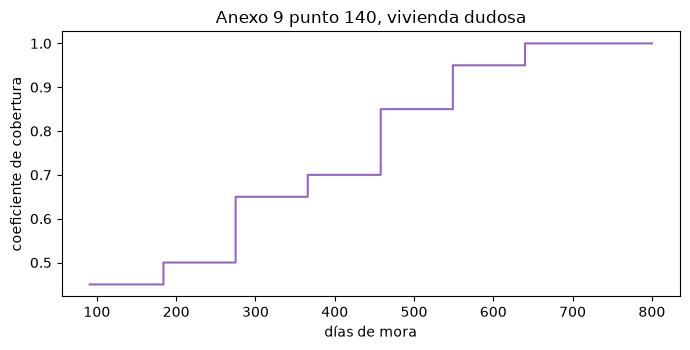

In [7]:
# Leer los coeficientes del Anexo 9 y dibujar la cobertura dudosa por días de mora
housing = (es.annex9_normal_coverage("B.1.1", "normal"), es.annex9_normal_coverage("B.1.1", "normal-special-watch"))
print("punto 144, vivienda, normal y vigilancia especial:", *housing)
print("punto 144, consumo y construcción, normal:", es.annex9_normal_coverage("B.2", "normal"),
      es.annex9_normal_coverage("A.1.1", "normal"))
coverage = es.annex9_coverage("B.1.1", "normal", 1000.0, [300.0])
print("cobertura: EAD 1000, garantías ajustadas 300, vivienda normal:", coverage)
try:
    es.annex9_coverage("B.1.1", "doubtful", 1000.0, [])
except ValueError as error:
    print("una cuenta dudosa sin días de mora se rechaza con", type(error).__name__)

days = np.arange(91, 801)
coefficients = [es.annex9_doubtful_coverage("B.1.1", int(d)) for d in days]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.step(days, coefficients, where="post", color="tab:purple")
ax.set_xlabel("días de mora")
ax.set_ylabel("coeficiente de cobertura")
ax.set_title("Anexo 9 punto 140, vivienda dudosa")
fig.tight_layout()
plt.show()

Los coeficientes del Anexo 9 son un objeto distinto de los factores B-1. Para el riesgo normal de vivienda el coeficiente es 0,007 y para vigilancia especial 0,18, 26 veces mayor, de modo que pasar una cuenta a vigilancia especial es el mayor paso individual; el crédito de consumo es 0,018 y la construcción 0,019. El coeficiente dudoso de vivienda es una escalera: 0,45 hasta 183 días, 0,50 desde 184, 0,65 a 365 y 1,0 a 700. Una cuenta de 1.000 con garantías de 300 en vivienda normal tiene una cobertura de 4,9, el coeficiente aplicado a los 700 no cubiertos. El rechazo de una cuenta dudosa sin mora muestra que el motor no inventa un coeficiente.

### Paso 5: las categorías versionadas del Anexo 9 y su etapa

La vista del Anexo 9 de Banco Andino está versionada por categoría de riesgo, con la exposición y la provisión de cada una. `annex9_category_to_stage` del motor asigna una categoría a una etapa de IFRS 9: normal a la Etapa 1, vigilancia especial a la Etapa 2 y dudoso a la Etapa 3. La celda pide al motor la etapa de cada categoría versionada e imprime la tasa de cobertura, la provisión sobre la exposición, junto a ella, de modo que el libro del Anexo 9 se pueda leer en el lenguaje IFRS 9 de los otros notebooks.

In [8]:
# Mapear con el motor las categorías versionadas del Anexo 9 a etapas y leer sus tasas de cobertura
categories = out["bde_detail"]["categories"]
for k, row in enumerate(categories, start=1):
    stage = es.annex9_category_to_stage(row["category"])
    rate = row["provision"] / row["exposure"]
    print("categoría", k, "| etapa asignada:", str(stage)[-1], "| tasa de cobertura:", round(rate, 6))

categoría 1 | etapa asignada: 1 | tasa de cobertura: 0.003723
categoría 2 | etapa asignada: 2 | tasa de cobertura: 0.057243
categoría 3 | etapa asignada: 3 | tasa de cobertura: 0.26521


La tasa de cobertura crece con la etapa que asigna el motor: 0,3723% para la categoría normal en la Etapa 1, 5,7243% para la vigilancia especial en la Etapa 2 y 26,5210% para la dudosa en la Etapa 3. Es la misma escalera que la cobertura IFRS 9 por etapa del notebook 02, construida aquí desde una tabla supervisora y no desde un modelo de vida completa, y hace justa la comparación del paso siguiente: los tres regímenes difieren en cómo llegan a la cobertura de cada etapa, no en si existen las etapas.

### Paso 6: una cartera, tres provisiones

Ahora los tres regímenes lado a lado en el escenario base. `outputs.comparison` entrega, para cada segmento, la provisión B-1, la PCE IFRS 9 y la cobertura del Anexo 9, más las líneas no asignadas (los ajustes IFRS 9). La celda suma los segmentos y las líneas no asignadas de cada régimen, imprime los tres totales y sus razones a B-1, e imprime la cobertura por segmento, la provisión sobre la exposición bruta. La figura dibuja esa cobertura para los seis segmentos.

CMF B-1    provisión, CLP miles de millones:   152.001
IFRS 9     provisión, CLP miles de millones:    97.592
Anexo 9    provisión, CLP miles de millones:    79.618
IFRS 9 sobre B-1: 0.6421
Anexo 9 sobre B-1: 0.5238
cobertura por segmento: B-1, IFRS 9, Anexo 9
  mortgage-ltv-le80        0.0011   0.0064   0.0000
  mortgage-ltv-gt80        0.0171   0.0107   0.0038
  consumer-instalment      0.0801   0.0259   0.0441
  consumer-cards           0.0844   0.0330   0.0332
  commercial-group         0.0187   0.0088   0.0093
  commercial-individual    0.0302   0.0255   0.0197


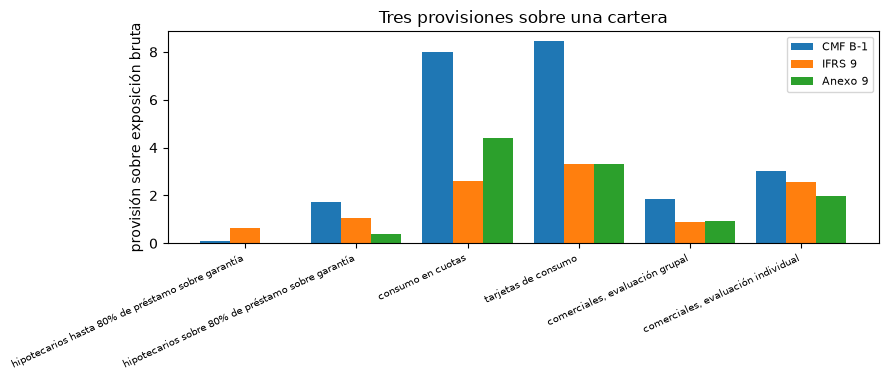

In [9]:
# Sumar los segmentos de cada régimen, comparar los tres totales y dibujar la cobertura por segmento
comparison = out["comparison"]
gross = {s["segment_id"]: s["gross_exposure"] for s in out["portfolio"]["segments"]}
KEYS = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
NAMES = ("CMF B-1", "IFRS 9", "Anexo 9")
totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in KEYS}
for key, name in zip(KEYS, NAMES):
    print(f"{name:10s} provisión, CLP miles de millones: {totals[key] / 1e9:9.3f}")
print("IFRS 9 sobre B-1:", round(totals[KEYS[1]] / totals[KEYS[0]], 4))
print("Anexo 9 sobre B-1:", round(totals[KEYS[2]] / totals[KEYS[0]], 4))
rates = {r["segment_id"]: [r[k] / gross[r["segment_id"]] for k in KEYS] for r in comparison["rows"]}
print("cobertura por segmento: B-1, IFRS 9, Anexo 9")
for segment, rate in rates.items():
    print(f"  {segment:22s}", *[f"{v:8.4f}" for v in rate])

x = np.arange(len(rates))
fig, ax = plt.subplots(figsize=(9, 3.9))
for k, (name, color) in enumerate(zip(NAMES, ("tab:blue", "tab:orange", "tab:green"))):
    ax.bar(x + (k - 1) * 0.27, [100 * r[k] for r in rates.values()], width=0.27, color=color, label=name)
ax.set_xticks(x)
ax.set_xticklabels([SEGMENT[s] for s in rates], rotation=25, ha="right", fontsize=7)
ax.set_ylabel("provisión sobre exposición bruta")
ax.set_title("Tres provisiones sobre una cartera")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La misma cartera recibe tres totales: 152,001 miles de millones de CLP bajo B-1, 97,592 bajo IFRS 9, con 0,324 de ajustes como líneas no asignadas, y 79,618 bajo el Anexo 9. IFRS 9 es 64,21% de B-1 y el Anexo 9 es 52,38%. El orden no es el mismo en cada segmento: las hipotecas hasta 80% de préstamo sobre garantía llevan 0,11% bajo B-1, 0,64% bajo IFRS 9 y nada bajo el Anexo 9, mientras que los préstamos de consumo en cuotas llevan 8,01%, 2,59% y 4,41%. Una sola razón entre regímenes esconde que los regímenes discrepan en direcciones opuestas en productos distintos, y los porcentajes de la figura son la provisión sobre la exposición bruta.

### Paso 7: el puente de B-1 a IFRS 9

La brecha entre dos regímenes es una suma de decisiones. `outputs.gap_bridge` lista los pasos desde el total B-1 al total IFRS 9: la base de medición (la PD, la pérdida dado el incumplimiento y las recuperaciones propias del banco frente a las matrices B-1, a doce meses, central y sin descuento), el horizonte de vida completa para la Etapa 2, la ponderación de escenarios por probabilidad, el descuento a la TIE original, el complemento del mínimo B-1 que IFRS 9 no tiene y los ajustes. La celda recorre los pasos en orden, imprimiendo el nivel acumulado, y la figura los dibuja como una cascada.

B-1                      152.001
base de medición         -92.548 ->    59.452
horizonte de vida completa   +17.134 ->    76.587
ponderación de escenarios   +11.625 ->    88.212
descuento                 +9.056 ->    97.268
mínimo B-1                +0.000 ->    97.268
ajustes                   +0.324 ->    97.592


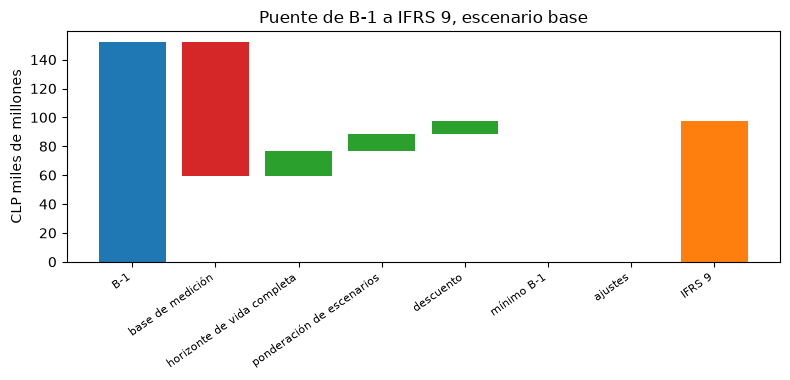

In [10]:
# Recorrer el puente de B-1 a IFRS 9 y dibujarlo
steps = out["gap_bridge"]["steps"]
level = totals[KEYS[0]] / 1e9
print(f"{'B-1':22s} {level:9.3f}")
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.bar(0, level, color="tab:blue")
labels = ["B-1"]
for i, step in enumerate(steps, start=1):
    amount = step["amount"] / 1e9
    bottom, color = (level, "tab:green") if amount >= 0 else (level + amount, "tab:red")
    ax.bar(i, abs(amount), bottom=bottom, color=color)
    level += amount
    labels.append(STEP[step["id"]])
    print(f"{STEP[step['id']]:22s} {amount:+9.3f} -> {level:9.3f}")
ax.bar(len(steps) + 1, level, color="tab:orange")
labels.append("IFRS 9")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("CLP miles de millones")
ax.set_title("Puente de B-1 a IFRS 9, escenario base")
fig.tight_layout()
plt.show()

Desde 152,001 miles de millones de CLP bajo B-1 la base de medición quita 92,548, la pérdida de vida completa de la Etapa 2 suma 17,134, la ponderación por probabilidad 11,625, el descuento a la TIE 9,056, el complemento del mínimo B-1 nada y los ajustes 0,324, lo que llega a 97,592, el total IFRS 9. La brecha de unos 54 mil millones es sobre todo el primer paso: la PD, la pérdida dado el incumplimiento y las recuperaciones propias del banco frente a las matrices B-1 son mucho menores que las matrices, y los pasos siguientes, que son las características de vida completa y prospectivas de IFRS 9, devuelven solo unos 38 mil millones de los 92,548 que se quitaron.

### Paso 8: el mismo banco bajo cinco tensiones

Los cinco archivos de tensión cambian la economía (una recesión, una caída de precios de viviendas, un choque de mora de consumo, un alza de la inflación UF y un caso combinado severo) y provisionan de nuevo el mismo banco bajo los tres regímenes. La celda lee las tres provisiones de cada escenario, las imprime con la razón de IFRS 9 sobre B-1, e imprime el cambio versionado del caso combinado severo frente al base. La figura dibuja la provisión de cada régimen en cada uno de los seis escenarios.

base                 B-1   152.0 | IFRS 9    97.6 | Anexo 9    79.6
                     IFRS 9 sobre B-1:  0.642
recesión             B-1   197.5 | IFRS 9   169.8 | Anexo 9   116.3
                     IFRS 9 sobre B-1:  0.860
precios de viviendas B-1   168.9 | IFRS 9   128.8 | Anexo 9    94.6
                     IFRS 9 sobre B-1:  0.763
mora de consumo      B-1   178.6 | IFRS 9   126.3 | Anexo 9    97.3
                     IFRS 9 sobre B-1:  0.707
inflación UF         B-1   166.9 | IFRS 9   117.4 | Anexo 9    85.6
                     IFRS 9 sobre B-1:  0.703
combinado severo     B-1   275.8 | IFRS 9   327.8 | Anexo 9   191.6
                     IFRS 9 sobre B-1:  1.189
combinado severo frente al base, CLP miles de millones (B-1, IFRS 9, Anexo 9):
123.8 230.2 112.0


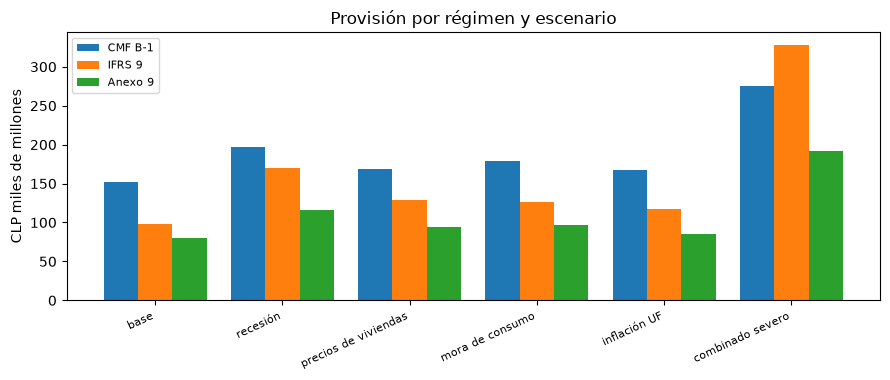

In [11]:
# Leer las tres provisiones en los seis escenarios y dibujarlas
regime_rows = {n: a["outputs"]["regimes"] for n, a in scenarios.items()}
by_regime = {n: {r["regime"]: r["total_provision"] / 1e9 for r in rs} for n, rs in regime_rows.items()}
for name, regimes in by_regime.items():
    b1, ifrs9_total, annex = regimes["cmf-b1"], regimes["ifrs9"], regimes["bde-annex9"]
    print(f"{SCENARIO[name]:20s} B-1 {b1:7.1f} | IFRS 9 {ifrs9_total:7.1f} | Anexo 9 {annex:7.1f}")
    print(f"{'':20s} IFRS 9 sobre B-1: {ifrs9_total / b1:6.3f}")
delta = scenarios["combined-severe"]["outputs"]["delta_vs_base"]
print("combinado severo frente al base, CLP miles de millones (B-1, IFRS 9, Anexo 9):")
changes = (delta["cmf_b1_delta"], delta["ifrs9_delta"], delta["bde_annex9_delta"])
print(*[round(c / 1e9, 1) for c in changes])

x = np.arange(len(by_regime))
fig, ax = plt.subplots(figsize=(9, 3.9))
for k, (regime, color, label) in enumerate((("cmf-b1", "tab:blue", "CMF B-1"), ("ifrs9", "tab:orange", "IFRS 9"),
                                            ("bde-annex9", "tab:green", "Anexo 9"))):
    ax.bar(x + (k - 1) * 0.27, [r[regime] for r in by_regime.values()], width=0.27, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels([SCENARIO[n] for n in by_regime], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("CLP miles de millones")
ax.set_title("Provisión por régimen y escenario")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El orden de los regímenes no sobrevive a toda tensión. La razón de IFRS 9 sobre B-1 es 0,642 en el escenario base y sube a 0,860 en la recesión, 0,763 con la caída de precios de viviendas, 0,707 con el choque de mora de consumo y 0,703 con el alza de la inflación UF. En el caso combinado severo es 1,189: IFRS 9 llega a 327,8 miles de millones frente a 275,8 de B-1. Del escenario base a ese caso B-1 sube 123,8 miles de millones, IFRS 9 230,2 y el Anexo 9 112,0. Una provisión basada en tablas se mueve con los tramos de mora y una pérdida esperada se mueve con el pronóstico, de modo que el régimen prospectivo es el que más reacciona cuando la economía se deteriora.

## Resultados

**Respuesta:** En el escenario base Banco Andino provisiona 152,001 miles de millones de CLP bajo B-1, 97,592 bajo IFRS 9 y 79,618 bajo el Anexo 9, de modo que IFRS 9 es 0,6421 de B-1, y la brecha es sobre todo una decisión: la base de medición sola quita 92,548 miles de millones, que el horizonte de vida completa (17,134), la ponderación de escenarios (11,625), el descuento (9,056) y los ajustes (0,324) solo devuelven en parte; el orden no sobrevive a una tensión severa, ya que en el escenario combinado severo IFRS 9 llega a 327,8 miles de millones frente a 275,8 de B-1.

- **Las tablas B-1 se leen como fueron transcritas.** Para una hipoteca con una razón préstamo sobre garantía entre 40% y 80% y sin mora, $PI = 0{,}019158$ y $PDI = 0{,}021955$, de modo que $PE = 0{,}000421$; en PVG 0,35 es 0,000002. Un préstamo comercial al día con una garantía a un PTVG de 0,8 tiene $PE = 0{,}005989$ y sin garantía 0,027938; las categorías individuales A1, A4 y B4 tienen 0,00036, 0,0175 y 0,43875.
- **Las reglas grupales se calculan como dice el compendio.** Con una exposición de 1.000, una $PE$ de 0,05 y 20% garantizado a 0,01 la provisión es 42,0. Banco Andino no tiene método interno, así que la provisión estándar es la aplicada en todos los segmentos grupales.
- **El mínimo y las provisiones adicionales son separados.** El mínimo de 0,50% de la cartera normal evaluada individualmente es 8.457,4 millones de CLP y no es vinculante; con una provisión de 5.000 millones lo sería con un complemento de 3.457,4. Las provisiones adicionales de 3.000 millones están dentro del rango del directorio y un monto de 20.000 se rechaza.
- **El Anexo 9 se lee como un coeficiente sobre el monto no cubierto.** El riesgo normal de vivienda es 0,007 y la vigilancia especial 0,18; el crédito de consumo 0,018; la construcción 0,019. Para el riesgo dudoso de vivienda el coeficiente es 0,45 hasta 183 días y 1,0 a 700. Las categorías se asignan a las Etapas 1, 2 y 3 con tasas de cobertura de 0,3723%, 5,7243% y 26,5210%.
- **Una cartera, tres totales.** IFRS 9 es 64,21% de B-1 y el Anexo 9 es 52,38%. Por segmento el orden cambia: las hipotecas hasta 80% de préstamo sobre garantía llevan 0,11% bajo B-1, 0,64% bajo IFRS 9 y nada bajo el Anexo 9, mientras que los préstamos de consumo en cuotas llevan 8,01%, 2,59% y 4,41%.
- **El puente es una lista de decisiones.** Desde 152,001 miles de millones bajo B-1 la base de medición quita 92,548, la pérdida de vida completa de la Etapa 2 suma 17,134, la ponderación por probabilidad 11,625, el descuento 9,056 y los ajustes 0,324, lo que da 97,592.
- **El orden de los regímenes no sobrevive a toda tensión.** IFRS 9 sobre B-1 es 0,642 en el escenario base y 0,860, 0,763, 0,707 y 0,703 en la recesión, la caída de precios de viviendas, el choque de mora de consumo y el alza de la inflación UF. En el caso combinado severo es 1,189. Del escenario base a ese caso B-1 sube 123,8 miles de millones, IFRS 9 230,2 y el Anexo 9 112,0.

Lo que este notebook no muestra: Banco Andino es sintético, sus choques, ajustes y provisiones adicionales son supuestos del caso, y la columna IFRS 9 es una medida de comparación que los bancos chilenos no registran sobre préstamos. La propuesta de reforma de la CMF de agosto de 2026 (escala de PI recalibrada, métodos internos) no está vigente y no se implementa; los números de punto del Anexo 9 son los de la Circular 6/2021. El notebook no dice nada sobre si algún banco real se provisionaría así.

## Resumen

- Los bancos chilenos registran provisiones B-1 sobre los préstamos, no deterioro IFRS 9; B-1 es una tabla de celdas $PE = PI \times PDI$ con una regla del máximo, un mínimo y una línea separada de provisiones adicionales, y el motor guarda cada tabla transcrita celda por celda.
- El Anexo 9 del Banco de España es un coeficiente sobre el monto no cubierto, por segmento y categoría, con una asignación a las etapas de IFRS 9.
- En un banco sintético los tres regímenes dan tres totales; la brecha entre B-1 e IFRS 9 es un puente de decisiones con nombre, dominado por la base de medición.
- El orden de los regímenes depende de la economía: IFRS 9 queda muy bajo B-1 en el escenario base y sobre él en el caso combinado severo.
- Banco Andino es sintético y sus choques son supuestos; la comparación enseña la mecánica, no valora a ningún banco real.

**Qué probar después.** Cambia el `pvg` y el tramo de mora de la búsqueda hipotecaria para leer otras celdas; entrega a `b1_group_max_rule` un monto interno sobre el estándar para un segmento grupal y recalcula el total B-1. Luego sigue con el notebook 07, que abre los modelos de PD de vida completa que alimentan la columna IFRS 9.

## Referencias

- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Capítulos A-2 (N 5) y B-1 (N 2, N 3, N 4 y N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 4/2017, norma 29 y Anejo 9 (BOE-A-2017-14334). https://www.boe.es/buscar/act.php?id=BOE-A-2017-14334
- Banco de España, Circular 6/2021 de 22 de diciembre (BOE-A-2021-21666): las tablas de los puntos 140, 144 y 172, aplicables desde el 30 de junio de 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm